In [11]:
import pandas as pd

In [12]:
import numpy as np

In [13]:
import matplotlib.pyplot as plt

In [31]:
import seaborn as sns

In [14]:
#Load thee dataset
df = pd.read_csv(r"C:\Users\mutun\Downloads\superstore_sales.csv", nrows = 9994)

In [15]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [16]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [17]:
#Remove rows that are entirely empty
df = df.dropna(how= 'all')

In [19]:
#Replace the 11 missing postal codes with 0
df['Postal Code'] = df['Postal Code'].fillna(0)

In [22]:
#Convert Order Date to an official datatime type
df['Order Date'] = pd.to_datetime(df['Order Date'])

In [23]:
#Create a new column showing only the Year and Month
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

In [25]:
#Grouping by Category, Region and Segment to sum up metrics
summary_table = df.groupby(['Category', 'Region', 'Segment']).agg({
    'Sales' : 'sum',
    'Profit' : 'sum'
}).reset_index()

In [27]:
#Plotting Monthly sales velocity(line Chart)

In [30]:
#Calculating sales by month and sort them in order
monthly_sales = df.groupby('Year-Month')['Sales'].sum().reset_index()
monthly_sales = monthly_sales.sort_values('Year-Month')

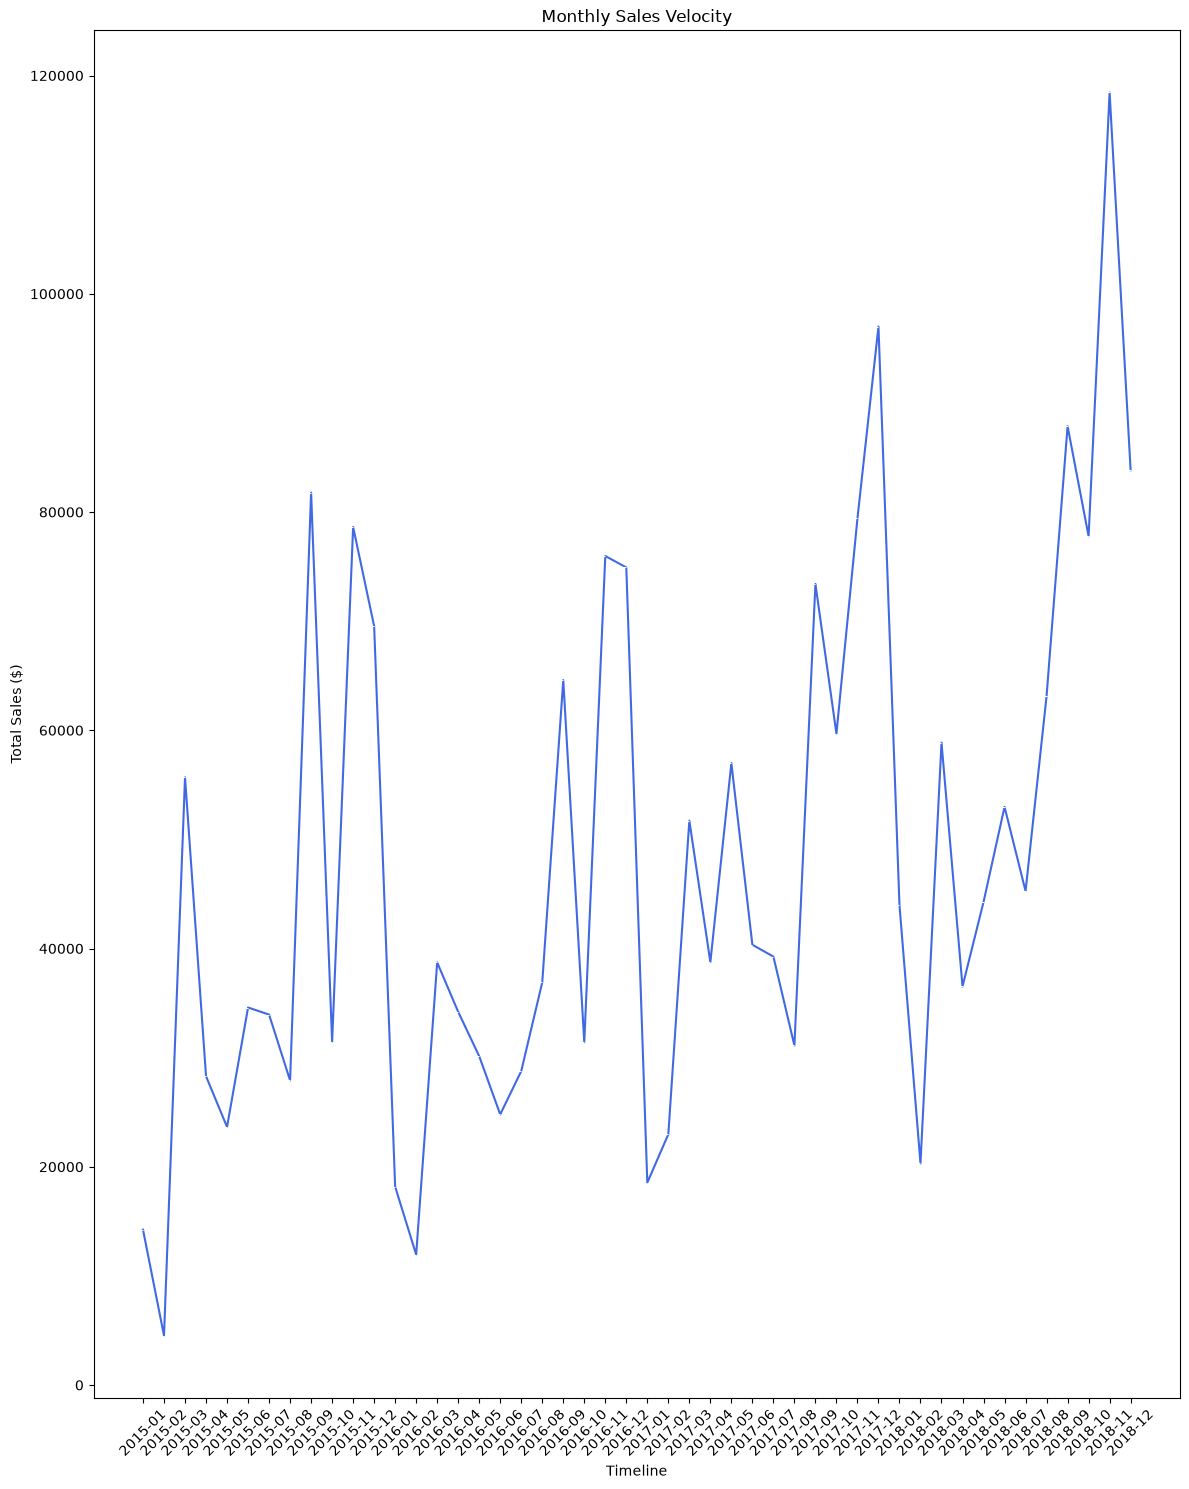

In [34]:
#Plot line chart
plt.figure(figsize = (12, 15))
sns.lineplot(data = monthly_sales, x = 'Year-Month', y='Sales', marker = 0, color = 'royalblue')

plt.title('Monthly Sales Velocity')
plt.xticks(rotation = 45)
plt.ylabel('Total Sales ($)')
plt.xlabel('Timeline')
plt.tight_layout()
plt.show()

In [35]:
#A scatter plot to analyze how Discount rates impact Profit margins

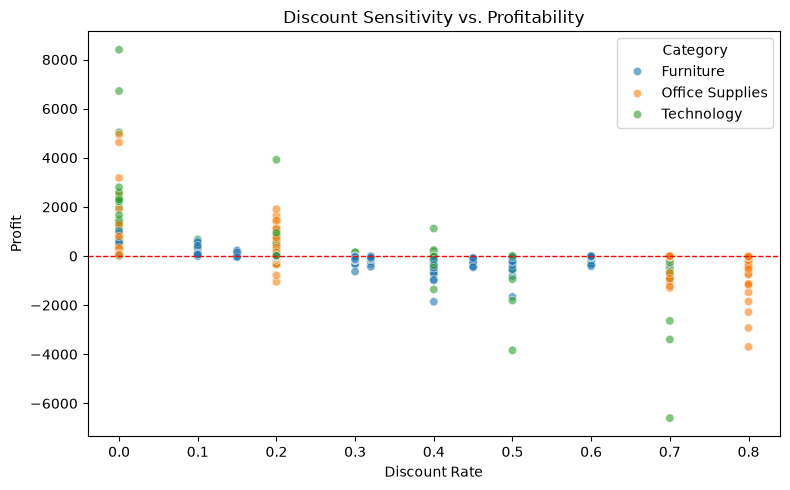

In [36]:
#Plotting Discount vs Profit
plt.figure(figsize = (8, 5))
sns.scatterplot(data = df, x = 'Discount', y= 'Profit', alpha = 0.6, hue = 'Category')
plt.axhline(0, color= 'red', linestyle = '--', linewidth = 1) #this is the baseline for zero profit
plt.title('Discount Sensitivity vs. Profitability')
plt.xlabel('Discount Rate')
plt.ylabel('Profit')
plt.tight_layout()
plt.show()

In [ ]:
#Executive Business Observations & Insights

# 1. Monthly Sales Velocity & Q4 Seasonality
# Observation: Sales data cosistemtly exhibits a major structural spike during the fourth quarter (November and December peaks), driven by holidays-season purchasing behavior. Conversely, Q1 (specifically January and February) shows a significant post-holiday period with the lowest monthly sales velocity of the fiscal year.
# Strategic Recommendation: Impement targeted promotional campaingns during the Q1 slump to liquidate trailing inventory, and scale up supply chain capacity by early October to avoid stockouts during peak Q4 velocity.

# 2. The Zero-Discount Profit Engine
# Observation: At a 0.0 discount rate, profitability is highly secure across all segments. Crucially, our highest-value outlier transactions occur here, with Technology (highlighted in green) generating peak individual profit reaching around $6,000 and $8,000 per order.
# Recommendation: Treat 20% as the hard operational ceiling for standard marketing promotions to preserve baseline transaction health.

# 3. Catastrophic Losses at High Discount Tiers (70% - 80%)
#Observation: High discount tiers create catastrophic financial leakages:
          # At 70% discount (0.7), Technology (highlighted in green) suffers a massive outlie loss dropping to nearly -$6,000.
          # At 80% discount (0.8), thereis a dense, high-frequency cluster of Office Supplies (highlighted in orange) consistently draining profits between -$1,000 and -$3,000.
#Recommandation: Immediately audit theSKU-level pricing rules causing 70% - 80% markdowns. Liquidating inventory at these rates is more costly than writing off or bundling the stock.